<a href="https://colab.research.google.com/github/nataga-10/chatbot_react/blob/main/K_means.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 2 · Clustering Jerárquico Aglomerativo — Dataset *Wine*
**CADI Introducción a Machine Learning — Universidad de Cundinamarca**
**Autora:** Angie Tatiana Reyes Sanchez

**Objetivo:** construir la jerarquía de agrupamientos de los 178 vinos, comparar cuatro criterios de enlace (*single, complete, average* y *Ward*), leer el dendrograma para decidir dónde cortar y comparar el resultado con K-means.


In [15]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("figuras", exist_ok=True)   # carpeta donde se guardan las figuras del informe
np.random.seed(42)

# Paleta de colores del proyecto (morados, rosas y lavandas)
PALETA = ["#6A3D9A", "#E7298A", "#1B9E77", "#F28E2B", "#5B8DEF", "#B07AA1"]
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 10,
    "axes.prop_cycle": plt.cycler(color=PALETA),
})

In [16]:
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

wine = load_wine()
X_std = StandardScaler().fit_transform(wine.data)
y_real = wine.target
print("Matriz estandarizada:", X_std.shape)

Matriz estandarizada: (178, 13)


## 1. ¿Cómo funciona? Ejemplo numérico pequeño
El algoritmo aglomerativo empieza con cada punto como su propio cluster y en cada paso **fusiona los dos clusters más cercanos**. Se muestra con 5 puntos en 2D para ver la matriz de distancias y la tabla de fusiones (*linkage matrix*) de SciPy.

Cálculo manual de la primera fusión, entre A(1, 1) y B(1.5, 1.2):
d = √((1.5 − 1)² + (1.2 − 1)²) = √0.29 = **0.539**, la menor distancia de la matriz.

Matriz de distancias euclidianas:


,A,B,C,D,E
A,0.000,0.539,5.657,5.890,8.000
B,0.539,0.000,5.166,5.381,7.503
C,5.657,5.166,0.000,0.539,5.657
D,5.890,5.381,0.539,0.000,5.166
E,8.000,7.503,5.657,5.166,0.000



Tabla de fusiones [cluster_i, cluster_j, distancia, n_puntos]:
[[0.    1.    0.539 2.   ]
 [2.    3.    0.539 2.   ]
 [5.    6.    5.166 4.   ]
 [4.    7.    5.166 5.   ]]

Paso 1: A y B se fusionan a distancia 0.539 (la menor de la matriz)


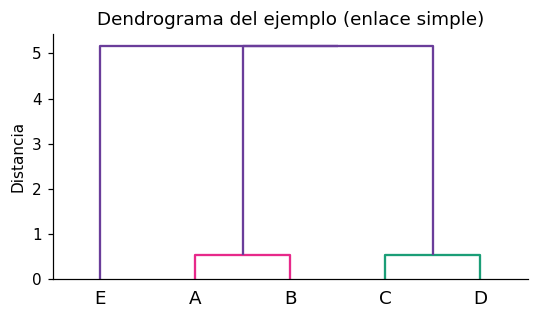

In [17]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist, squareform

P = np.array([[1, 1], [1.5, 1.2], [5, 5], [5.5, 4.8], [9, 1]])
D = squareform(pdist(P))
print("Matriz de distancias euclidianas:")
display(pd.DataFrame(D, index=list("ABCDE"), columns=list("ABCDE")).round(3))

Lp = linkage(P, method="single")
print("\nTabla de fusiones [cluster_i, cluster_j, distancia, n_puntos]:")
print(np.round(Lp, 3))
print("\nPaso 1: A y B se fusionan a distancia", round(D[0, 1], 3), "(la menor de la matriz)")

fig, ax = plt.subplots(figsize=(5, 3))
dendrogram(Lp, labels=list("ABCDE"), color_threshold=2, ax=ax)
ax.set(title="Dendrograma del ejemplo (enlace simple)", ylabel="Distancia"); ax.grid(False)
plt.tight_layout(); plt.show()

## 2. Comparación de criterios de enlace
- **Single:** distancia mínima entre puntos de los dos clusters (tiende a formar "cadenas").
- **Complete:** distancia máxima.
- **Average:** distancia promedio entre todos los pares.
- **Ward** (Ward, 1963): fusiona los clusters que menos aumentan la varianza interna.

Para cada uno se calcula el **coeficiente de correlación cofenética**, que mide qué tan fielmente el dendrograma conserva las distancias originales, y, cortando en 3 clusters, la silueta y el ARI frente a los cultivares reales.

In [18]:
from sklearn.metrics import silhouette_score, adjusted_rand_score

dist = pdist(X_std)
filas, enlaces = [], {}
for metodo in ["single", "complete", "average", "ward"]:
    L = linkage(X_std, method=metodo)
    enlaces[metodo] = L
    c, _ = cophenet(L, dist)
    etq = fcluster(L, t=3, criterion="maxclust")
    filas.append({"enlace": metodo, "corr. cofenética": round(c, 4),
                  "tamaños (k=3)": str(sorted(np.bincount(etq)[1:].tolist(), reverse=True)),
                  "silueta": round(silhouette_score(X_std, etq), 4),
                  "ARI vs real": round(adjusted_rand_score(y_real, etq), 4)})
comparacion = pd.DataFrame(filas)
display(comparacion)

,enlace,corr. cofenética,tamaños (k=3),silueta,ARI vs real
0,single,0.5436,"[174, 3, 1]",0.1827,-0.0068
1,complete,0.5917,"[69, 58, 51]",0.2038,0.5771
2,average,0.7591,"[174, 3, 1]",0.1575,-0.0054
3,ward,0.6623,"[64, 58, 56]",0.2774,0.7899


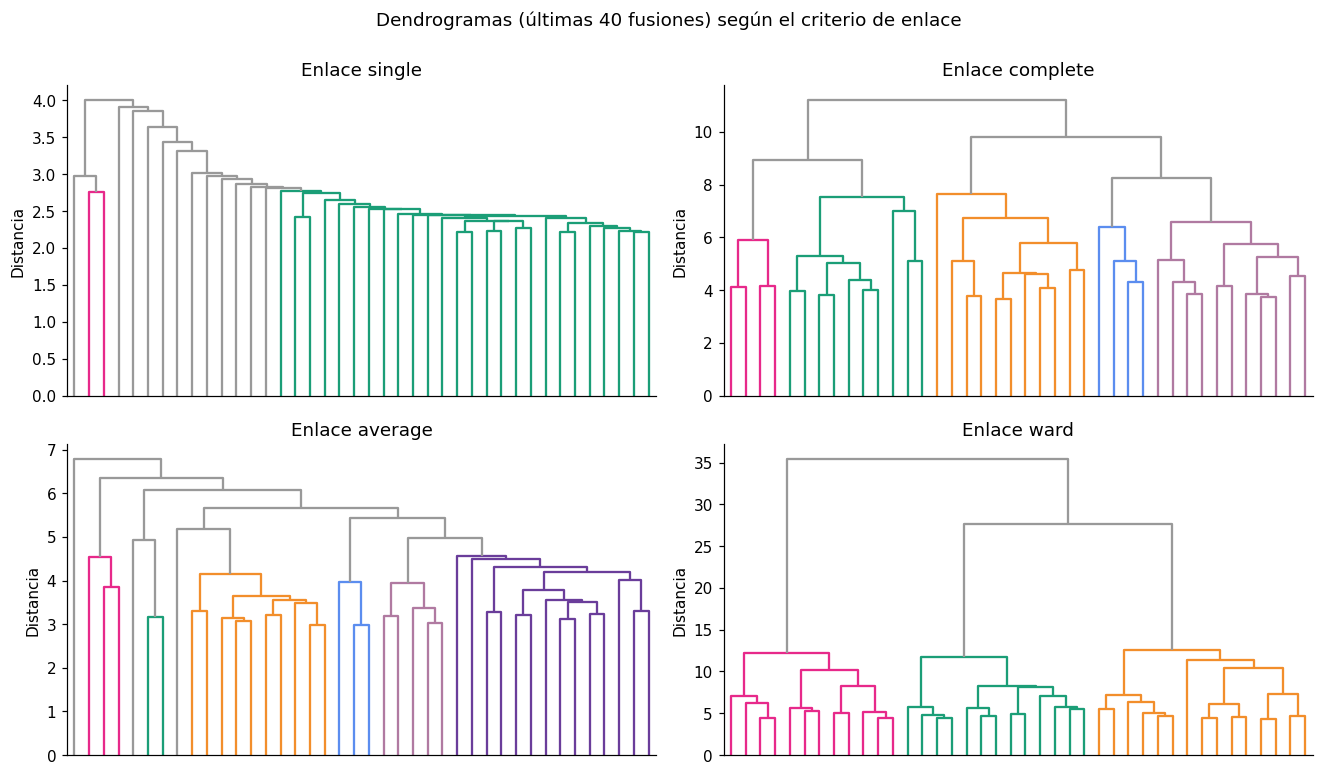

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, metodo in zip(axes.ravel(), enlaces):
    dendrogram(enlaces[metodo], ax=ax, no_labels=True, color_threshold=None,
               above_threshold_color="#999999", truncate_mode="lastp", p=40)
    ax.set_title(f"Enlace {metodo}"); ax.set_ylabel("Distancia"); ax.grid(False)
plt.suptitle("Dendrogramas (últimas 40 fusiones) según el criterio de enlace", y=1.0)
plt.tight_layout(); plt.savefig("figuras/fig05_dendrogramas_enlaces.png", dpi=200, bbox_inches="tight"); plt.show()

## 3. Dendrograma de Ward y elección del corte
En el dendrograma, el número natural de clusters se lee buscando el **salto vertical más grande** entre fusiones consecutivas: cortar justo debajo de ese salto evita unir grupos muy distintos.

Alturas de las últimas 10 fusiones: [35.4  27.65 12.57 12.23 11.72 11.38 10.4  10.15  8.29  8.25]
Pasar de 1 a 2 clusters baja la altura en 7.75
Pasar de 2 a 3 clusters baja la altura en 15.08
Pasar de 3 a 4 clusters baja la altura en 0.34
Pasar de 4 a 5 clusters baja la altura en 0.51
Pasar de 5 a 6 clusters baja la altura en 0.35
Pasar de 6 a 7 clusters baja la altura en 0.98

Umbral de corte elegido: 20.11  ->  3 clusters


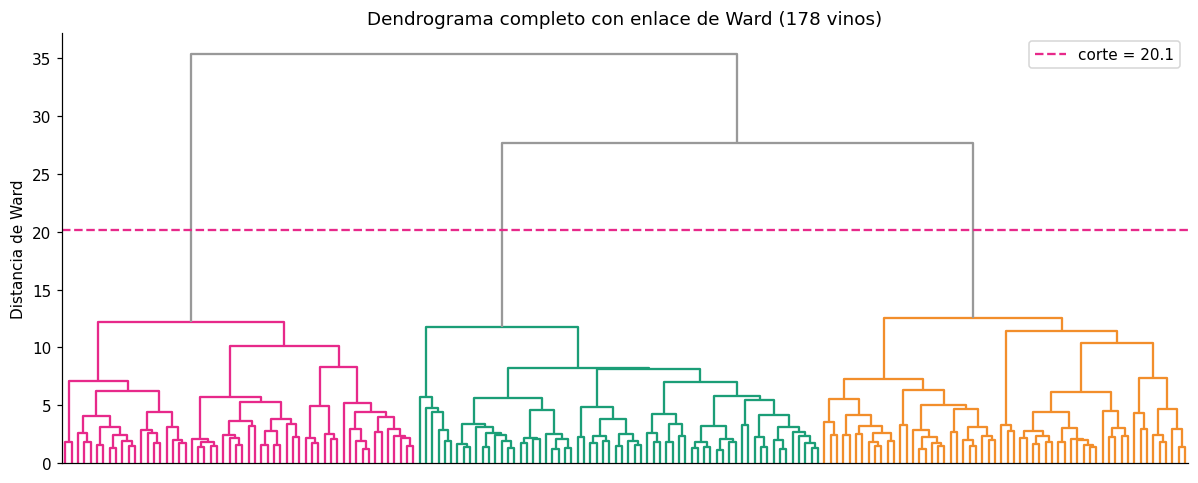

In [20]:
L_ward = enlaces["ward"]
alturas = L_ward[:, 2]
ultimas = alturas[-10:][::-1]
saltos = -np.diff(ultimas)
print("Alturas de las últimas 10 fusiones:", np.round(ultimas, 2))
for i, s in enumerate(saltos[:6]):
    print(f"Pasar de {i+1} a {i+2} clusters baja la altura en {s:.2f}")

umbral = (ultimas[1] + ultimas[2]) / 2     # punto medio entre la 2.ª y 3.ª fusión más alta
print(f"\nUmbral de corte elegido: {umbral:.2f}  ->  3 clusters")

fig, ax = plt.subplots(figsize=(11, 4.5))
dendrogram(L_ward, ax=ax, no_labels=True, color_threshold=umbral, above_threshold_color="#999999")
ax.axhline(umbral, ls="--", color=PALETA[1], label=f"corte = {umbral:.1f}")
ax.set(title="Dendrograma completo con enlace de Ward (178 vinos)", ylabel="Distancia de Ward"); ax.grid(False); ax.legend()
plt.tight_layout(); plt.savefig("figuras/fig06_dendrograma_ward.png", dpi=200, bbox_inches="tight"); plt.show()

## 4. Modelo final con Scikit-learn y comparación con K-means

Tamaños jerárquico: [58 56 64]
Silueta jerárquico: 0.2774
ARI jerárquico vs real: 0.7899
ARI K-means   vs real: 0.8975
ARI jerárquico vs K-means (acuerdo entre algoritmos): 0.853


Cluster jerárquico,0,1,2
Cultivar real,,,
0,0,0,59
1,58,8,5
2,0,48,0


Vinos asignados a grupos distintos por los dos algoritmos: 9


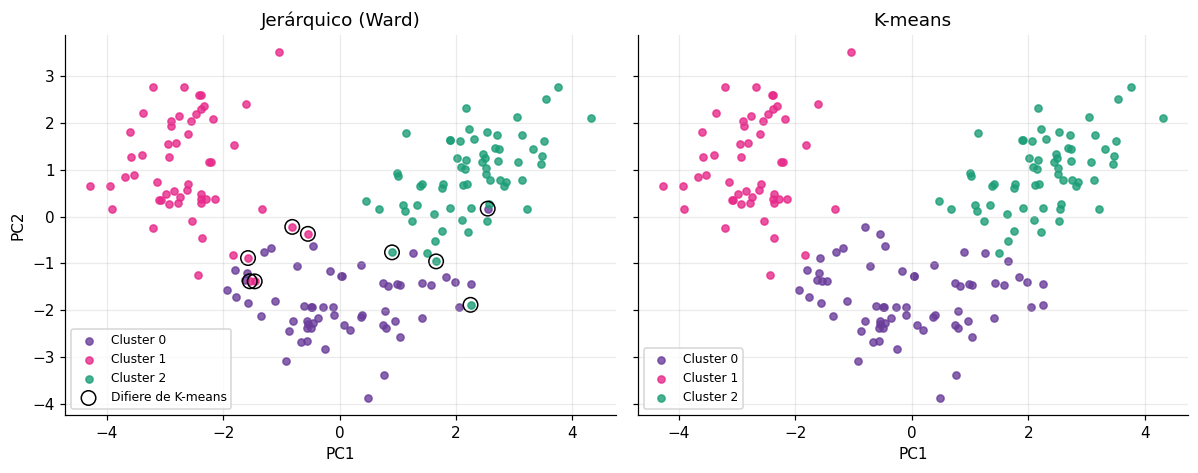

In [21]:
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA

agg = AgglomerativeClustering(n_clusters=3, linkage="ward")
etq_agg = agg.fit_predict(X_std)
etq_km = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X_std)

print("Tamaños jerárquico:", np.bincount(etq_agg))
print("Silueta jerárquico:", round(silhouette_score(X_std, etq_agg), 4))
print("ARI jerárquico vs real:", round(adjusted_rand_score(y_real, etq_agg), 4))
print("ARI K-means   vs real:", round(adjusted_rand_score(y_real, etq_km), 4))
print("ARI jerárquico vs K-means (acuerdo entre algoritmos):", round(adjusted_rand_score(etq_km, etq_agg), 4))
display(pd.crosstab(pd.Series(y_real, name="Cultivar real"), pd.Series(etq_agg, name="Cluster jerárquico")))

# Los números de cluster son arbitrarios: se renombran los del jerárquico para que coincidan con K-means
mapa = pd.crosstab(etq_agg, etq_km).idxmax(axis=1).to_dict()
etq_agg_al = np.array([mapa[e] for e in etq_agg])
distintos = etq_agg_al != etq_km
print("Vinos asignados a grupos distintos por los dos algoritmos:", distintos.sum())

Z = PCA(n_components=2).fit_transform(X_std)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4), sharex=True, sharey=True)
for c in range(3):
    ax[0].scatter(*Z[etq_agg_al == c].T, s=22, alpha=.8, color=PALETA[c], label=f"Cluster {c}")
    ax[1].scatter(*Z[etq_km == c].T, s=22, alpha=.8, color=PALETA[c], label=f"Cluster {c}")
ax[0].scatter(*Z[distintos].T, s=90, facecolors="none", edgecolors="black", label="Difiere de K-means")
ax[0].set(title="Jerárquico (Ward)", xlabel="PC1", ylabel="PC2"); ax[1].set(title="K-means", xlabel="PC1")
ax[0].legend(fontsize=8); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("figuras/fig07_jerarquico_vs_kmeans.png", dpi=200, bbox_inches="tight"); plt.show()

## 5. Análisis de resultados
1. **Criterio de enlace.** *Single* y *average* producen un cluster gigante (174 vinos) y dos casi vacíos por el efecto de encadenamiento (ARI ≈ 0), aunque *average* tenga la mayor correlación cofenética (0.759): conservar bien las distancias no garantiza grupos útiles. *Ward* da grupos equilibrados (64/58/56), la mejor silueta (0.277) y el mejor ARI (0.790).
2. **Corte del dendrograma.** Con Ward, pasar de 2 a 3 clusters reduce la altura de fusión en 15.08 (27.65 − 12.57), mientras que pasar de 3 a 4 solo la reduce en 0.34. El salto grande confirma k = 3, igual que el codo y la silueta del Notebook 1.
3. **Comparación con K-means.** Ambos coinciden en gran medida (ARI entre ellos = 0.853; solo 9 vinos cambian de grupo, la mayoría del cultivar 1). K-means logra mejor ARI (0.898 vs 0.790) porque optimiza globalmente la inercia, mientras que el jerárquico no puede deshacer una fusión temprana.
4. **Ventaja del jerárquico.** No exige fijar *k* de antemano y el dendrograma muestra la estructura a todas las escalas; su costo es mayor (memoria O(n²)), lo que lo limita a conjuntos medianos.
